In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import sys
sys.path.insert(0, r"c:\users\arthu\documents\swittz-epfl\phd\code\lib\site-packages")
sys.path.append('../')
from pygraphon.norm import MseProbaEdge, MaeProbaEdge, AUCEdge, AUPRCEdge
from pygraphon.plots.plot_matrices import spy

from pygraphon.estimators import SAS, TV_FL, FusedLasso

In [105]:
from pygraphon.estimators import FusedLasso
from pygraphon.graphons import common_graphons
from pygraphon.norm import JensenShannonDivergenceDistance, EarthMoversDistance, HellingerDistance, SimpleDifferenceDistance
n = 100
estimators = {g: {"SAS": None, "TV_FLJS": None, "EMD": None} for _,g in enumerate(common_graphons.values())}

for j,g in enumerate(common_graphons.values()):
    adj_mat = g.draw(n=n, exchangeable=False)
    est_FL = FusedLasso()
    est_FL.fit(adj_mat)
    break



C:\Users\verdeyme\Desktop\Code\pygraphon\src\pygraphon\estimators\FusedLasso.py:92: RuntimeWarning: divide by zero encountered in log
  np.log(scipy.stats.binom.pmf(M_tour[indices], 1, theta_hat_mat[indices]))


Best lambda:  0.06309573444801933


In [17]:
from pygraphon.graphons import common_graphons
from pygraphon.norm import JensenShannonDivergenceDistance, EarthMoversDistance, HellingerDistance, SimpleDifferenceDistance
from tqdm.notebook import tqdm
n = 50
estimators = {g: {"SAS": None, "TV_FL": None, "EMD": None} for _,g in enumerate(common_graphons.values())}
adjs = []
Ps = []

def remove_disconnected(A):
    idx = np.where(np.sum(A, axis=0) != 0)[0]
    return A[idx][:,idx]

for j,g in enumerate(common_graphons.values()):
    adj_mat = g.draw(n=n, exchangeable=False)
    random_perm = np.random.permutation(n)
    adj_mat = adj_mat[random_perm][:,random_perm]
    Ps.append(g.get_edge_probabilities(n,False,True)[random_perm][:,random_perm])
    adjs.append(adj_mat)
    est_sas = SAS()
    est_sas.fit(adj_mat)
    est_tv_fl = TV_FL(distance=JensenShannonDivergenceDistance())# FusedLasso(distance = SimpleDifferenceDistance())
    est_tv_fl.fit(adj_mat)
    estimators[g]["SAS"] = est_sas
    estimators[g]["TV_FL"] = est_tv_fl


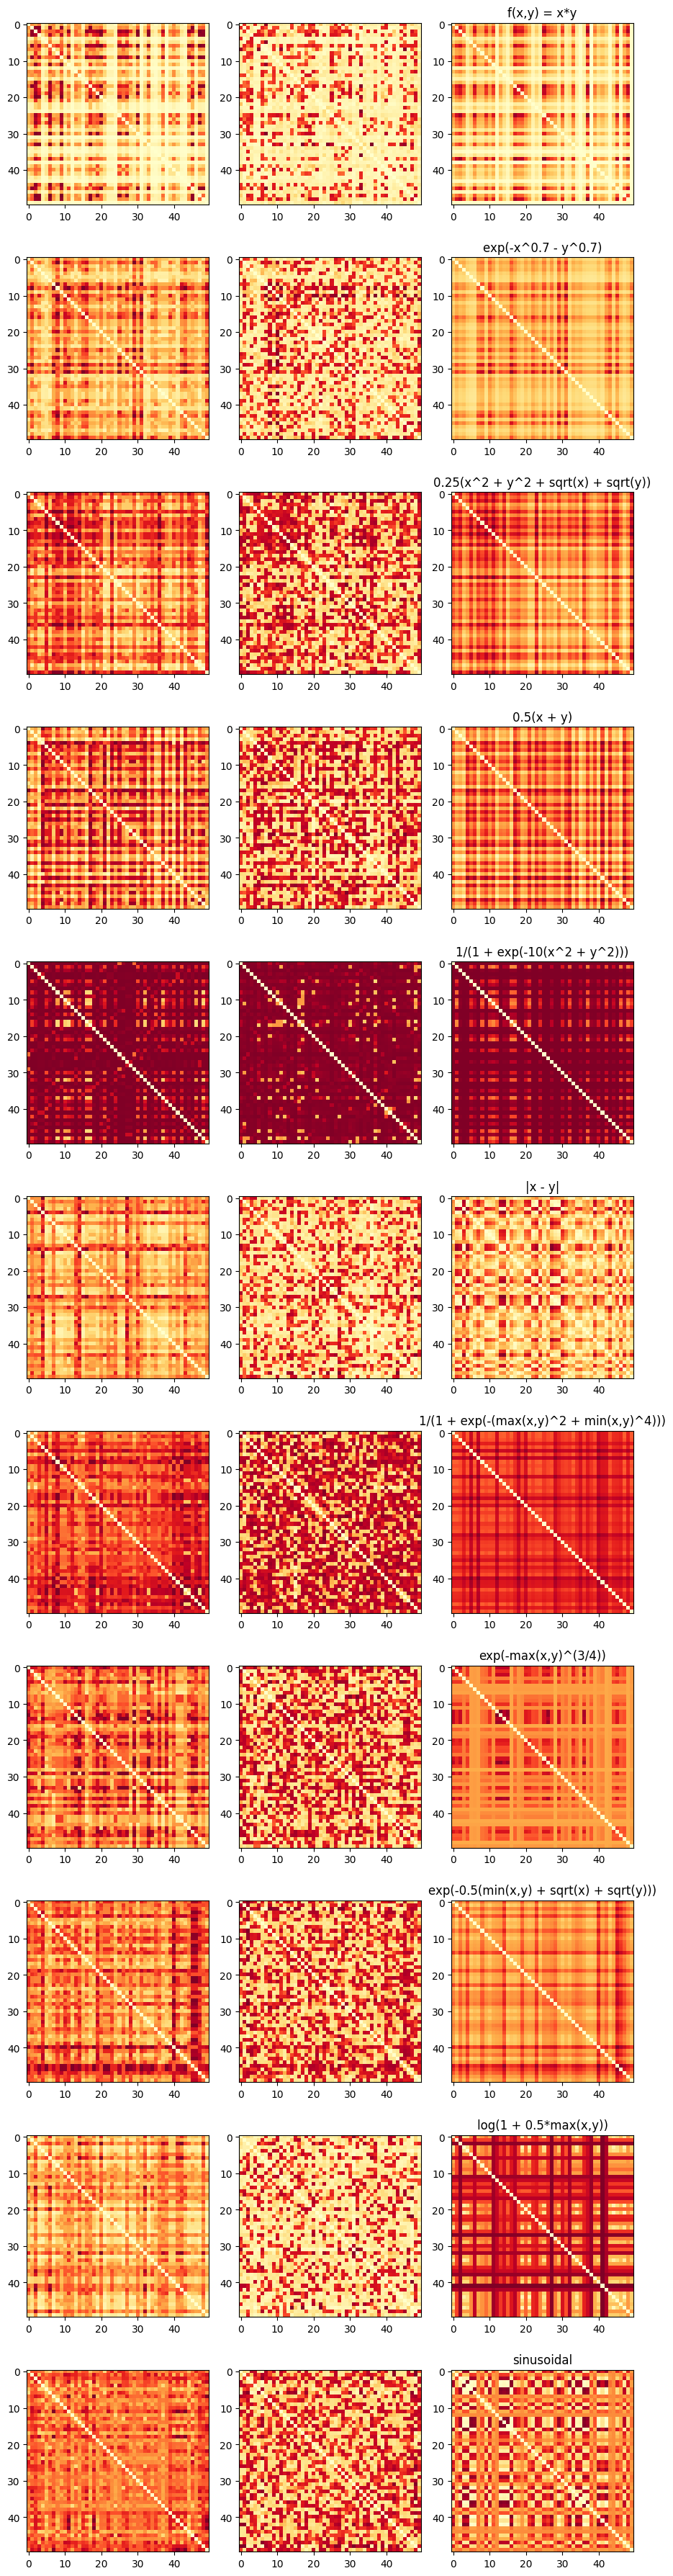

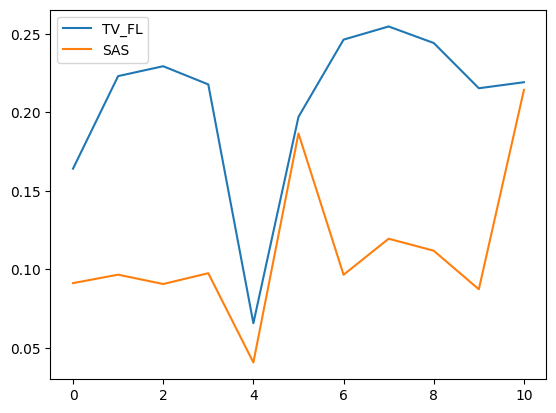

In [18]:
from palettable.colorbrewer.sequential import YlOrRd_9
# To get the colors as a list of RGB tuples:
colors = YlOrRd_9.mpl_colors
hex_colors = YlOrRd_9.hex_colors
import matplotlib.cm as cm
import matplotlib.colors as colors
cmap = cm.get_cmap('YlOrRd')
fig_size = 3
if True:
    fig, axes = plt.subplots(nrows=len(common_graphons.values()), ncols=3, figsize=(3*fig_size, 12*fig_size))
    for j,g in enumerate(common_graphons.values()):
        axes[j,0].imshow(estimators[g]["SAS"].get_edge_connectivity(), cmap = cmap)
        axes[j,1].imshow(estimators[g]["TV_FL"].get_edge_connectivity(), cmap = cmap)
        axes[j,2].imshow(Ps[j], cmap = cmap)
        axes[j,2].set_title(str(g))
    #plt.colorbar(axes[0,0].imshow(estimators[g]["SAS"].get_edge_connectivity(), cmap = cmap), ax=axes[0,0])
    plt.tight_layout()
    plt.show()

mse_fl = []
mse_sas = []
for j,g in enumerate(common_graphons.values()):
    mse_fl.append(np.mean(np.abs(Ps[j] - estimators[g]["TV_FL"].get_edge_connectivity())))
    mse_sas.append(np.mean(np.abs(Ps[j] - estimators[g]["SAS"].get_edge_connectivity())))

plt.plot(mse_fl, label="TV_FL")
plt.plot(mse_sas, label="SAS")
plt.legend()
plt.show()